# Day 5b: Improvements to the CNN (per-clip normalisation + masking)
Needs Days 1-5 (features/X_aug.npy from Day 5 and models/norm.npz from Day 4).
Only ONE thing to edit: the BASE address in the first code cell.
It trains 3 CNNs (about 5 minutes each) and compares them on the VALIDATION set.
The test set is NOT used here.

In [ ]:

BASE = r"C:\Users\Abdul Rehman\Documents\Projects\emotion-recognition"    

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score

BASE = Path(BASE)
EPOCHS = 60

df = pd.read_csv(BASE / "data" / "metadata.csv")
X = np.load(BASE / "features" / "X_mfcc.npy")           # (1440, 40, 130)
y = np.load(BASE / "features" / "y.npy")
X_aug = np.load(BASE / "features" / "X_aug.npy")        # (2880, 40, 130) augmented TRAINING clips
y_aug = np.load(BASE / "features" / "y_aug.npy")
norm0 = np.load(BASE / "models" / "norm.npz")           # global stats from Day 4

tr = (df["actor"] <= 16).values
va = df["actor"].between(17, 20).values
print("Train:", tr.sum(), "| Augmented:", len(X_aug), "| Validation:", va.sum())

Train: 960 | Augmented: 2880 | Validation: 240


Per-clip normalisation ("CMN"): subtract each clip's OWN average from MFCC coefficients 1-39.
This removes part of the speaker's voice colour, so the model focuses more on the emotion.
Coefficient 0 (overall loudness) is kept as it is, because loudness helps tell emotions apart.

In [ ]:

def cmn(x):                                              
    valid = np.any(x != 0, axis=0)                       
    if valid.sum() < 2:
        valid[:] = True
    out = x.copy()
    out[1:, valid] = x[1:, valid] - x[1:, valid].mean(axis=1, keepdims=True)
    return out.astype(np.float32)

def cmn_batch(A):
    return np.stack([cmn(a) for a in A])

Xc, Xaug_c = cmn_batch(X), cmn_batch(X_aug)

# Global statistics AFTER per-clip normalisation (from the training clips only)
mean_c = Xc[tr].mean(axis=(0, 2))[:, None]               # (40, 1)
std_c = Xc[tr].std(axis=(0, 2))[:, None] + 1e-8
np.savez(BASE / "models" / "norm_cmn.npz", mean=mean_c, std=std_c)
print("Saved models/norm_cmn.npz")

In [2]:
# Model, masking, and helpers
def build_cnn(lr=1e-3, dropout=0.4, width=32):
    m = models.Sequential([
        layers.Input(shape=(40, 130, 1)),
        layers.Conv2D(width, 3, padding="same", activation="relu"), layers.BatchNormalization(momentum=0.9), layers.MaxPooling2D(2),
        layers.Conv2D(width * 2, 3, padding="same", activation="relu"), layers.BatchNormalization(momentum=0.9), layers.MaxPooling2D(2),
        layers.Conv2D(width * 4, 3, padding="same", activation="relu"), layers.BatchNormalization(momentum=0.9), layers.GlobalAveragePooling2D(),
        layers.Dropout(dropout), layers.Dense(64, activation="relu"), layers.Dense(8, activation="softmax")])
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def rand_band(max_w, axis_len, b):
    """One random band (start, width) per clip along one axis. Returns a (B, axis_len) True/False mask."""
    w = tf.random.uniform([b], 0, max_w + 1, dtype=tf.int32)
    start = tf.cast(tf.random.uniform([b]) * tf.cast(axis_len - w + 1, tf.float32), tf.int32)
    idx = tf.range(axis_len)[tf.newaxis, :]
    return (idx >= start[:, tf.newaxis]) & (idx < (start + w)[:, tf.newaxis])

def spec_mask(x, y_, sw, max_time=20, max_freq=6):
    """Blank out a random block of time frames and a random block of MFCC rows (training only)."""
    shp = tf.shape(x)
    b, f, t = shp[0], shp[1], shp[2]
    time_m = rand_band(max_time, t, b)                   # (B, T)
    freq_m = rand_band(max_freq, f, b)                   # (B, F)
    mask = freq_m[:, :, tf.newaxis, tf.newaxis] | time_m[:, tf.newaxis, :, tf.newaxis]
    return tf.where(mask, tf.zeros_like(x), x), y_, sw

def make_train_ds(Xtr, ytr, cw_arr, use_mask, seed, batch=32):
    cw_t = tf.constant(cw_arr, dtype=tf.float32)
    ds = tf.data.Dataset.from_tensor_slices((Xtr, ytr))
    ds = ds.shuffle(len(Xtr), seed=seed, reshuffle_each_iteration=True)
    ds = ds.map(lambda a, b_: (a, b_, tf.gather(cw_t, b_)))     # class weights as sample weights
    ds = ds.batch(batch)
    if use_mask:
        ds = ds.map(spec_mask)
    return ds.prefetch(1)

def get_callbacks():
    return [tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=20, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="loss", factor=0.5, patience=5, min_lr=1e-5)]

RESULTS = BASE / "results.csv"
def save_result(name, acc, f1):
    row = pd.DataFrame([{"model": name, "val_accuracy": round(float(acc), 4), "val_macro_f1": round(float(f1), 4)}])
    if RESULTS.exists():
        old = pd.read_csv(RESULTS)
        old = old[old["model"] != name]
        row = pd.concat([old, row], ignore_index=True)
    row.to_csv(RESULTS, index=False)

def get_arrays(use_cmn):
    if use_cmn:
        A, A_aug, m, s = Xc, Xaug_c, mean_c, std_c
    else:
        A, A_aug, m, s = X, X_aug, norm0["mean"], norm0["std"]
    prep = lambda a: ((a - m) / s)[..., np.newaxis].astype(np.float32)
    return prep(np.concatenate([A[tr], A_aug])), prep(A[va])

y_train = np.concatenate([y[tr], y_aug])
cw_arr = compute_class_weight("balanced", classes=np.arange(8), y=y_train)

def run(name, use_cmn, use_mask, seed=42):
    print(f"\n===== {name} =====")
    tf.keras.utils.set_random_seed(seed)
    Xtr, Xva = get_arrays(use_cmn)
    ds = make_train_ds(Xtr, y_train, cw_arr, use_mask, seed)
    model = build_cnn()
    model.fit(ds, validation_data=(Xva, y[va]), epochs=EPOCHS, callbacks=get_callbacks(), verbose=2)
    pred = model.predict(Xva, verbose=0).argmax(axis=1)
    acc, f1 = accuracy_score(y[va], pred), f1_score(y[va], pred, average="macro")
    print(f"{name}: validation accuracy {acc:.3f} | macro-F1 {f1:.3f}")
    save_result(name, acc, f1)
    return acc, f1

In [3]:

experiments = {
    "CNN + aug + masking":        (False, True),
    "CNN + aug + CMN":            (True, False),
    "CNN + aug + CMN + masking":  (True, True),
}
scores = {}
for name, (use_cmn, use_mask) in experiments.items():
    scores[name] = run(name, use_cmn, use_mask)


===== CNN + aug + masking =====
Epoch 1/60


c:\Users\Abdul Rehman\Documents\Projects\emotion-recognition\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


120/120 - 27s - 228ms/step - accuracy: 0.2966 - loss: 1.8470 - val_accuracy: 0.3708 - val_loss: 1.6259 - learning_rate: 0.0010
Epoch 2/60
120/120 - 22s - 180ms/step - accuracy: 0.4190 - loss: 1.5592 - val_accuracy: 0.4333 - val_loss: 1.4509 - learning_rate: 0.0010
Epoch 3/60
120/120 - 22s - 180ms/step - accuracy: 0.4781 - loss: 1.3977 - val_accuracy: 0.4208 - val_loss: 1.4456 - learning_rate: 0.0010
Epoch 4/60
120/120 - 21s - 178ms/step - accuracy: 0.5232 - loss: 1.2984 - val_accuracy: 0.3958 - val_loss: 1.6460 - learning_rate: 0.0010
Epoch 5/60
120/120 - 21s - 176ms/step - accuracy: 0.5555 - loss: 1.2035 - val_accuracy: 0.4417 - val_loss: 1.4922 - learning_rate: 0.0010
Epoch 6/60
120/120 - 21s - 177ms/step - accuracy: 0.5841 - loss: 1.1515 - val_accuracy: 0.3917 - val_loss: 1.7874 - learning_rate: 0.0010
Epoch 7/60
120/120 - 21s - 175ms/step - accuracy: 0.6096 - loss: 1.0646 - val_accuracy: 0.5125 - val_loss: 1.2908 - learning_rate: 0.0010
Epoch 8/60
120/120 - 21s - 178ms/step - accur

NameError: name 'Xc' is not defined

In [5]:
def cmn(x):
    valid = np.any(x != 0, axis=0)
    if valid.sum() < 2:
        valid[:] = True
    out = x.copy()
    out[1:, valid] = x[1:, valid] - x[1:, valid].mean(axis=1, keepdims=True)
    return out.astype(np.float32)

def cmn_batch(A):
    return np.stack([cmn(a) for a in A])

Xc, Xaug_c = cmn_batch(X), cmn_batch(X_aug)

mean_c = Xc[tr].mean(axis=(0, 2))[:, None]
std_c = Xc[tr].std(axis=(0, 2))[:, None] + 1e-8
np.savez(BASE / "models" / "norm_cmn.npz", mean=mean_c, std=std_c)
print("Saved models/norm_cmn.npz | Xc:", Xc.shape, "| Xaug_c:", Xaug_c.shape)

Saved models/norm_cmn.npz | Xc: (1440, 40, 130) | Xaug_c: (2880, 40, 130)


In [6]:
r = pd.read_csv(RESULTS).set_index("model")
scores = {"CNN + aug + masking": (r.loc["CNN + aug + masking", "val_accuracy"],
                                  r.loc["CNN + aug + masking", "val_macro_f1"])}
for name in ["CNN + aug + CMN", "CNN + aug + CMN + masking"]:
    use_cmn, use_mask = experiments[name]
    scores[name] = run(name, use_cmn, use_mask)


===== CNN + aug + CMN =====
Epoch 1/60


c:\Users\Abdul Rehman\Documents\Projects\emotion-recognition\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


120/120 - 29s - 244ms/step - accuracy: 0.3125 - loss: 1.8008 - val_accuracy: 0.3000 - val_loss: 1.7164 - learning_rate: 0.0010
Epoch 2/60
120/120 - 22s - 184ms/step - accuracy: 0.4672 - loss: 1.4378 - val_accuracy: 0.3750 - val_loss: 1.7698 - learning_rate: 0.0010
Epoch 3/60
120/120 - 22s - 183ms/step - accuracy: 0.5396 - loss: 1.2579 - val_accuracy: 0.3542 - val_loss: 1.8534 - learning_rate: 0.0010
Epoch 4/60
120/120 - 22s - 183ms/step - accuracy: 0.6034 - loss: 1.0858 - val_accuracy: 0.4875 - val_loss: 1.4159 - learning_rate: 0.0010
Epoch 5/60
120/120 - 22s - 185ms/step - accuracy: 0.6568 - loss: 0.9485 - val_accuracy: 0.3792 - val_loss: 1.8860 - learning_rate: 0.0010
Epoch 6/60
120/120 - 22s - 184ms/step - accuracy: 0.7148 - loss: 0.8114 - val_accuracy: 0.4375 - val_loss: 1.8814 - learning_rate: 0.0010
Epoch 7/60
120/120 - 22s - 185ms/step - accuracy: 0.7625 - loss: 0.6825 - val_accuracy: 0.5208 - val_loss: 1.5416 - learning_rate: 0.0010
Epoch 8/60
120/120 - 22s - 186ms/step - accur

c:\Users\Abdul Rehman\Documents\Projects\emotion-recognition\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


120/120 - 25s - 210ms/step - accuracy: 0.2859 - loss: 1.8584 - val_accuracy: 0.2708 - val_loss: 1.9967 - learning_rate: 0.0010
Epoch 2/60
120/120 - 21s - 173ms/step - accuracy: 0.4130 - loss: 1.5569 - val_accuracy: 0.4250 - val_loss: 1.5479 - learning_rate: 0.0010
Epoch 3/60
120/120 - 21s - 173ms/step - accuracy: 0.4872 - loss: 1.3931 - val_accuracy: 0.3042 - val_loss: 2.0760 - learning_rate: 0.0010
Epoch 4/60
120/120 - 21s - 173ms/step - accuracy: 0.5133 - loss: 1.2801 - val_accuracy: 0.4000 - val_loss: 1.8240 - learning_rate: 0.0010
Epoch 5/60
120/120 - 21s - 174ms/step - accuracy: 0.5596 - loss: 1.1848 - val_accuracy: 0.4417 - val_loss: 1.5559 - learning_rate: 0.0010
Epoch 6/60
120/120 - 41s - 342ms/step - accuracy: 0.5935 - loss: 1.1151 - val_accuracy: 0.3250 - val_loss: 2.1922 - learning_rate: 0.0010
Epoch 7/60
120/120 - 21s - 173ms/step - accuracy: 0.6229 - loss: 1.0220 - val_accuracy: 0.5500 - val_loss: 1.2595 - learning_rate: 0.0010
Epoch 8/60
120/120 - 21s - 173ms/step - accur

                    model  val_accuracy  val_macro_f1
             Baseline SVM        0.4708        0.4536
                      CNN        0.5333        0.4837
                     LSTM        0.4583        0.4519
       CNN + augmentation        0.6458        0.6357
      LSTM + augmentation        0.5292        0.5218
      CNN + aug + masking        0.6625        0.6589
          CNN + aug + CMN        0.6708        0.6645
CNN + aug + CMN + masking        0.6583        0.6559

Chosen: 'CNN + aug + CMN' (macro-F1 0.665 beats the Day 5 CNN + augmentation 0.636)
Saved models/improve_config.json: {'use_cmn': True, 'use_mask': False}


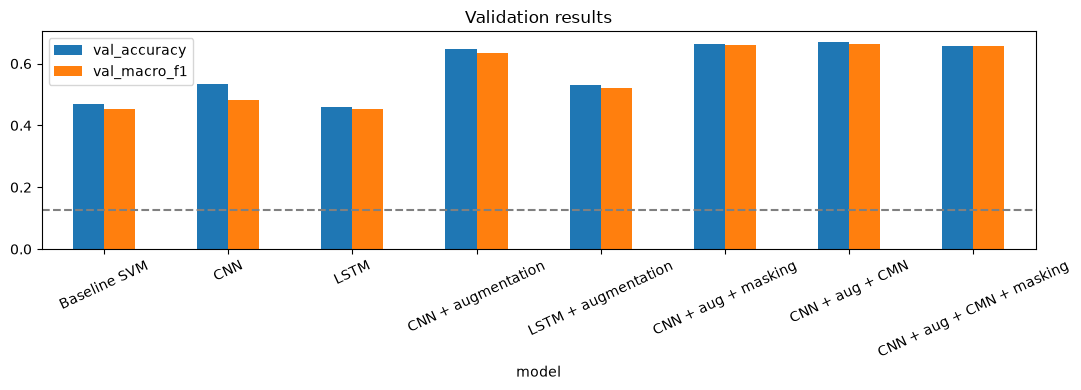

In [7]:

results = pd.read_csv(RESULTS)
print(results.to_string(index=False))

baseline_row = results[results["model"] == "CNN + augmentation"]
baseline_f1 = float(baseline_row["val_macro_f1"].iloc[0]) if len(baseline_row) else 0.0

best_name = max(scores, key=lambda k: scores[k][1])
best_f1 = scores[best_name][1]

if best_f1 > baseline_f1 + 0.01:
    use_cmn, use_mask = experiments[best_name]
    print(f"\nChosen: '{best_name}' (macro-F1 {best_f1:.3f} beats the Day 5 CNN + augmentation {baseline_f1:.3f})")
else:
    use_cmn, use_mask = False, False
    print(f"\nNone of the new setups clearly beat the Day 5 CNN + augmentation ({baseline_f1:.3f}). "
          f"Day 6 will use the plain setup.")

json.dump({"use_cmn": use_cmn, "use_mask": use_mask}, open(BASE / "models" / "improve_config.json", "w"))
print("Saved models/improve_config.json:", {"use_cmn": use_cmn, "use_mask": use_mask})

ax = results.set_index("model")[["val_accuracy", "val_macro_f1"]].plot(kind="bar", figsize=(11, 4), rot=25)
ax.axhline(1 / 8, color="gray", linestyle="--"); ax.set_title("Validation results")
plt.tight_layout(); plt.show()